# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
# owid-co2-data.csv must be in the same folder as this notebook
raw = pd.read_csv('owid-co2-data.csv')

# The 15 countries used in the course, with their region
countries = {
    'United States': 'North America', 'Canada': 'North America',
    'Mexico': 'Latin America', 'Brazil': 'Latin America',
    'China': 'Asia', 'India': 'Asia', 'Japan': 'Asia', 'South Korea': 'Asia', 'Indonesia': 'Asia',
    'Russia': 'Europe', 'Germany': 'Europe', 'United Kingdom': 'Europe', 'France': 'Europe',
    'South Africa': 'Africa', 'Australia': 'Oceania',
}

df = raw[raw['country'].isin(countries) & raw['year'].between(2000, 2022)].copy()
df = df.rename(columns={'country': 'Country', 'year': 'Year', 'co2': 'CO2_Mt'})
df['Region'] = df['Country'].map(countries)
df = df[['Country', 'Region', 'Year', 'CO2_Mt', 'co2_per_capita']].rename(columns={'co2_per_capita': 'CO2_per_capita'})
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
        Country   Region  Year   CO2_Mt  CO2_per_capita
3654  Australia  Oceania  2000  349.898          18.288
3655  Australia  Oceania  2001  357.668          18.469
3656  Australia  Oceania  2002  362.425          18.495
3657  Australia  Oceania  2003  370.784          18.708
3658  Australia  Oceania  2004  382.005          19.056


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <ArrowStringArray>
[     'Australia',         'Brazil',         'Canada',          'China',
         'France',        'Germany',          'India',      'Indonesia',
          'Japan',         'Mexico',         'Russia',   'South Africa',
    'South Korea', 'United Kingdom',  'United States']
Length: 15, dtype: str

CO2 range: 281.054 to 11711.808 Mt

Regional averages (2022):
Region
Asia             3387.5
North America    2801.5
Europe            737.4
Latin America     466.9
Africa            428.8
Oceania           384.1
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

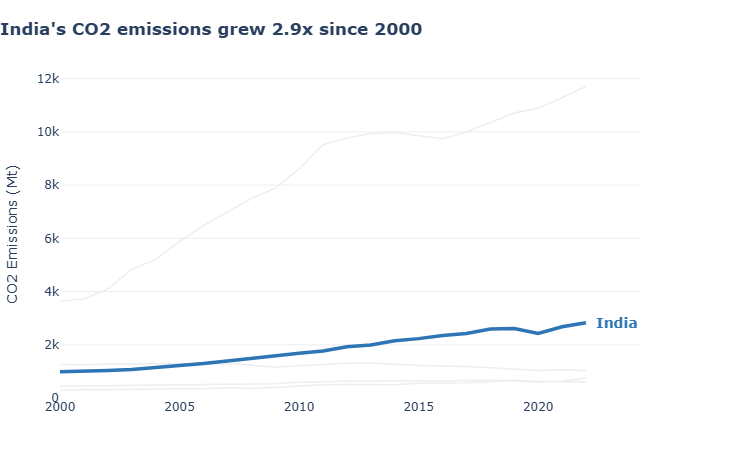

In [3]:
# Task — Multi-series line with highlight
import plotly.graph_objects as go

# 1. All Asian countries
asia = df[df['Region'] == 'Asia'].sort_values(['Country', 'Year'])

# 2. Choose the highlighted country and compute the facts for the title from the data
highlight = 'India'
first_year, last_year = asia['Year'].min(), asia['Year'].max()
h = asia[asia['Country'] == highlight].set_index('Year')['CO2_Mt']
growth = h[last_year] / h[first_year]          # e.g. 2.8 -> "2.8x"

HIGHLIGHT_COLOR = '#2E75B6'
GREY = '#EEEEEE'

fig = go.Figure()

# 3. Context lines first (grey, thin), highlighted line last so it sits on top
for country in asia['Country'].unique():
    if country == highlight:
        continue
    d = asia[asia['Country'] == country]
    fig.add_trace(go.Scatter(x=d['Year'], y=d['CO2_Mt'], mode='lines',
                             line=dict(color=GREY, width=1.5),
                             name=country, showlegend=False,
                             hovertemplate=f'{country}: ' + '%{y:,.0f} Mt<extra></extra>'))

fig.add_trace(go.Scatter(x=h.index, y=h.values, mode='lines',
                         line=dict(color=HIGHLIGHT_COLOR, width=3.5),
                         name=highlight, showlegend=False,
                         hovertemplate=f'{highlight}: ' + '%{y:,.0f} Mt<extra></extra>'))

# 4. Direct label at the end of the highlighted line (no legend)
fig.add_annotation(x=last_year, y=h[last_year],
                   text=f'<b>{highlight}</b>',
                   showarrow=False, xanchor='left', xshift=8,
                   font=dict(color=HIGHLIGHT_COLOR, size=14))

# 5. Clean layout: no border, no vertical grid, light horizontal grid, horizontal text
fig.update_layout(
    template='plotly_white',
    title=dict(text=f"<b>{highlight}'s CO2 emissions grew {growth:.1f}x since {first_year}</b>",
               x=0.0, xanchor='left'),
    height=450,
    margin=dict(l=60, r=90, t=70, b=40),
    xaxis=dict(showgrid=False, showline=False, title='', dtick=5, tickangle=0),
    yaxis=dict(showgrid=True, gridcolor='#EEEEEE', zeroline=False, showline=False,
               title='CO2 Emissions (Mt)', rangemode='tozero'),
)
fig.show()
